# 一、贝叶斯分类器

In [2]:
import sys
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import MLPClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

# 自实现模型（models/exp3/）
sys.path.insert(0, ".")
from models.exp3.naive_bayes import MultinomialNB as MyNB
from models.exp3.bp_network import MLPClassifier as MyMLP


/home/yukari/PycharmProjects/machine_learning/.venv/lib/python3.12/site-packages/joblib/_multiprocessing_helpers.py:44: UserWarning: [Errno 13] Permission denied.  joblib will operate in serial mode
  warnings.warn("%s.  joblib will operate in serial mode" % (e,))


# a.编写Python代码实验贝叶斯分类器

In [3]:
nb_model = MultinomialNB()

## b.加载数据集后，进行基本的数据清洗和处理

In [4]:
ham_path = "data/exp3/email/ham/*.txt"
spam_path = "data/exp3/email/spam/*.txt"

emails = []
labels = []

for file in glob.glob(ham_path):
    with open(file, "r", encoding="utf-8", errors="ignore") as f:
        emails.append(f.read())
        labels.append(0)

for file in glob.glob(spam_path):
    with open(file, "r", encoding="utf-8", errors="ignore") as f:
        emails.append(f.read())
        labels.append(1)

df = pd.DataFrame({"text": emails, "label": labels})

In [5]:
df["text"] = df["text"].str.lower()

## c.将数据集分为训练集和测试集，使用K折交叉验证来评估模型效果

In [6]:
X = df["text"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [7]:
vectorizer = TfidfVectorizer(lowercase=True, stop_words="english")

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

In [8]:
model = Pipeline([("tfidf", TfidfVectorizer(lowercase=True, stop_words="english")),("nb", MultinomialNB())])

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")

print("每折准确率：")
for i, score in enumerate(cv_scores, 1):
    print("第{}折：{:.2f}%".format(i, score * 100))

print("\n平均准确率：{:.2f}%".format(cv_scores.mean() * 100))

每折准确率：
第1折：100.00%
第2折：100.00%
第3折：90.00%
第4折：80.00%
第5折：100.00%

平均准确率：94.00%


In [10]:
# 自实现的 5 折交叉验证：每一折都只在训练部分上拟合 TF-IDF
cv_manual = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
manual_scores = []
for train_idx, test_idx in cv_manual.split(X, y):
    vec = TfidfVectorizer(lowercase=True, stop_words="english")
    A = vec.fit_transform(X.iloc[train_idx])
    B = vec.transform(X.iloc[test_idx])
    m = MyNB(alpha=1.0).fit(A, y.iloc[train_idx])
    manual_scores.append(accuracy_score(y.iloc[test_idx], m.predict(B)))

print("自实现每折准确率：")
for i, s in enumerate(manual_scores, 1):
    print("第{}折：{:.2f}%".format(i, s * 100))
print("\n自实现平均准确率：{:.2f}%".format(np.mean(manual_scores) * 100))
print("与调包实现的每折结果完全一致：",
      bool(np.allclose(np.array(manual_scores), cv_scores)))


自实现每折准确率：
第1折：100.00%
第2折：100.00%
第3折：90.00%
第4折：80.00%
第5折：100.00%

自实现平均准确率：94.00%
与调包实现的每折结果完全一致： True


## d.训练贝叶斯分类器并对测试集进行预测

In [11]:
nb_model.fit(X_train_tfidf, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[20.,20.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.69,-0.69]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 584)","[[0.46,0. ,0.41,...,0. ,0.56,0. ], [0.97,0.18,0.64,...,1.92,0. ,0.14]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 584)","[[-6.13,-6.5 ,-6.16,...,-6.5 ,-6.05,-6.5 ], [-5.84,-6.35,-6.03,...,-5.45,-6.52,-6.39]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,584


In [12]:
y_pred = nb_model.predict(X_test_tfidf)

## e.计算并报告模型的准确率、混淆矩阵、精确率、召回率和F1分数

In [13]:
accuracy = accuracy_score(y_test, y_pred)
print("\n测试集准确率：{:.2f}%".format(accuracy * 100))


测试集准确率：90.00%


In [14]:
cm = confusion_matrix(y_test, y_pred)
print("\n混淆矩阵：")
print(cm)


混淆矩阵：
[[5 0]
 [1 4]]


In [15]:
print("\n分类报告：")
report = classification_report(y_test, y_pred, target_names=["Ham", "Spam"])
print(report)


分类报告：
              precision    recall  f1-score   support

         Ham       0.83      1.00      0.91         5
        Spam       1.00      0.80      0.89         5

    accuracy                           0.90        10
   macro avg       0.92      0.90      0.90        10
weighted avg       0.92      0.90      0.90        10



In [16]:
# 自实现的多项式朴素贝叶斯
my_nb = MyNB(alpha=1.0)
my_nb.fit(X_train_tfidf, y_train)
my_nb_pred = my_nb.predict(X_test_tfidf)

nb_comparison = pd.DataFrame({
    "实现方式": ["sklearn 调包", "自实现"],
    "测试准确率(%)": [accuracy * 100, accuracy_score(y_test, my_nb_pred) * 100],
})
print("两种朴素贝叶斯实现的对比：")
print(nb_comparison.to_string(index=False))
print("\n两种实现的预测一致率：{:.2%}".format((my_nb_pred == y_pred).mean()))
print("类条件概率（对数）的最大差异：{:.2e}".format(
    np.max(np.abs(nb_model.feature_log_prob_ - my_nb.feature_log_prob_))))


两种朴素贝叶斯实现的对比：
      实现方式  测试准确率(%)
sklearn 调包      90.0
       自实现      90.0

两种实现的预测一致率：100.00%
类条件概率（对数）的最大差异：0.00e+00


## f.绘制分类结果的混淆矩阵图

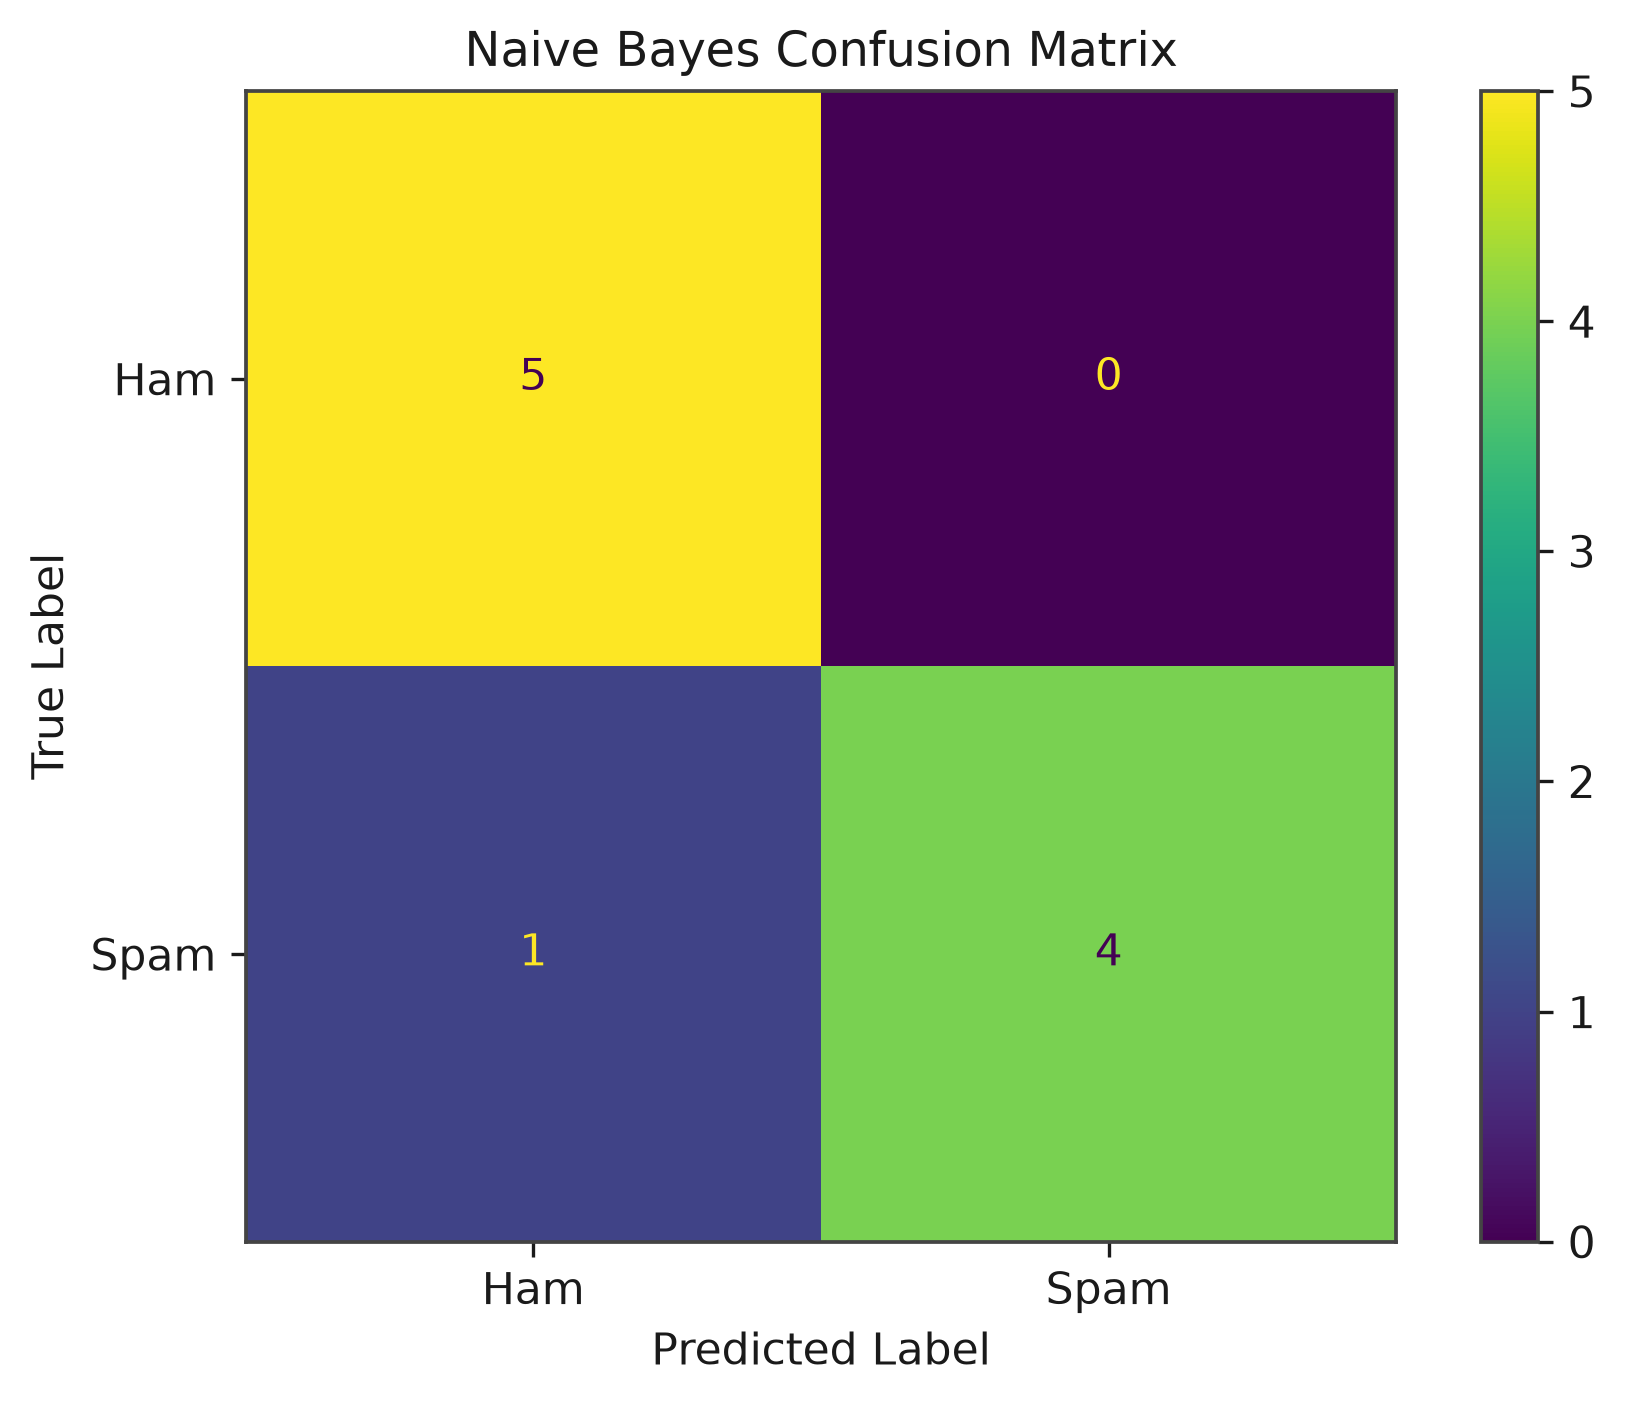

In [17]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Ham", "Spam"])
disp.plot()
plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

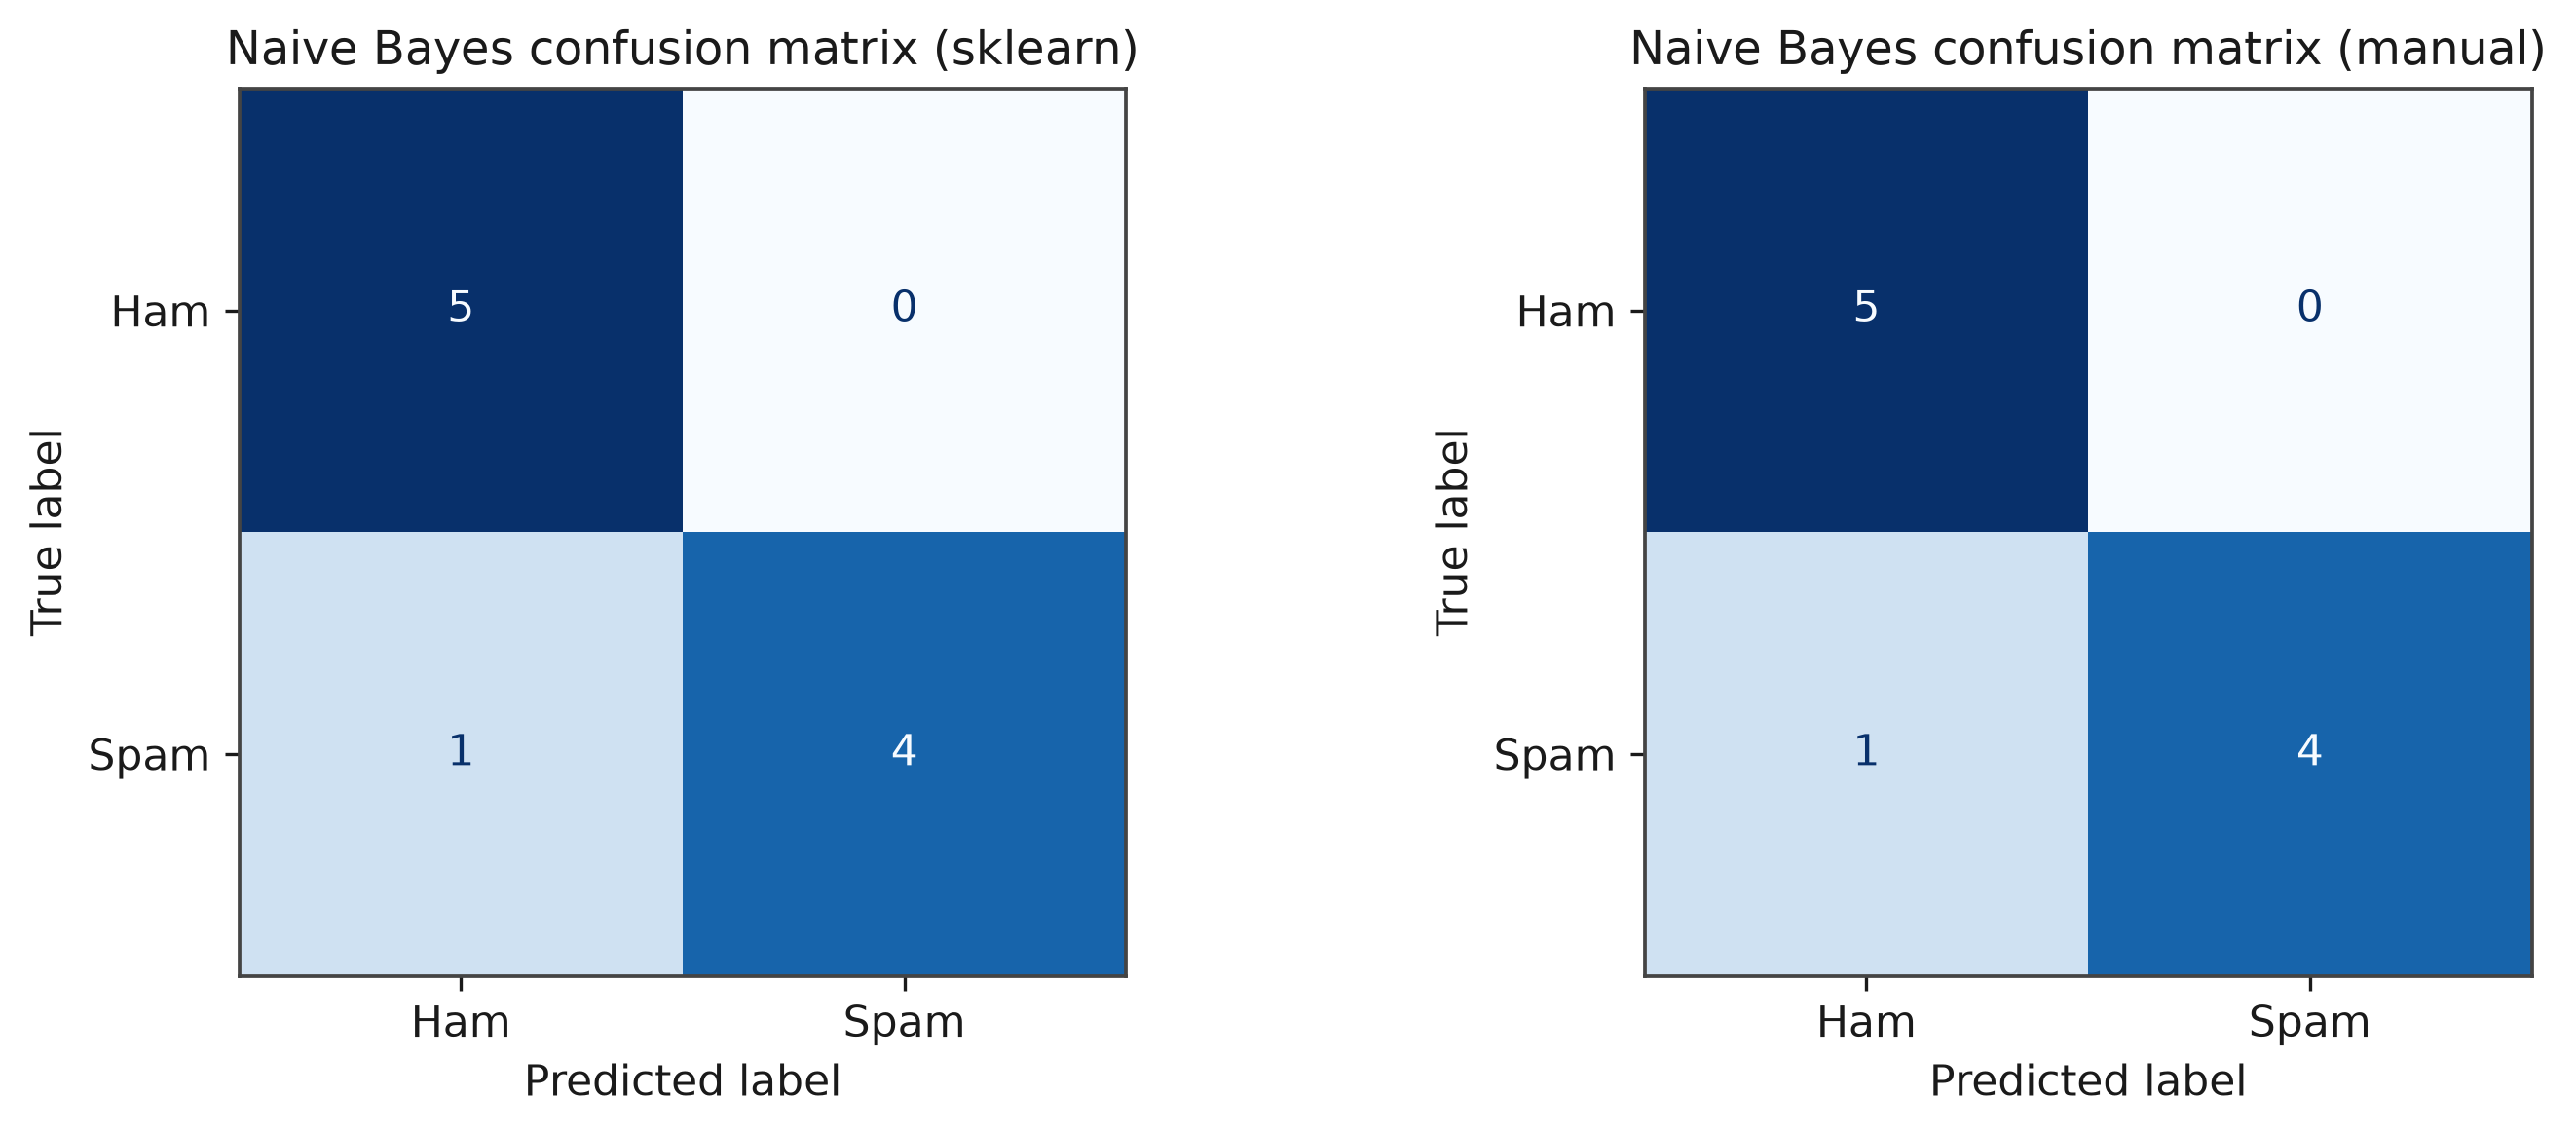

In [18]:
# 两种实现的混淆矩阵对比
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (cm_show, title) in zip(axes, [(cm, "sklearn"),
                                      (confusion_matrix(y_test, my_nb_pred), "manual")]):
    ConfusionMatrixDisplay(confusion_matrix=cm_show, display_labels=["Ham", "Spam"]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title("Naive Bayes confusion matrix ({})".format(title))
plt.tight_layout()
plt.show()


# 二、BP算法

## a.读入数据

In [19]:
df = pd.read_csv('data/exp3/winequality-red.csv', sep=";")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


## b.将红酒分为两个等级，其中评分3、4、5的为”bad”品质，评分为6、7、8的分为“good”品质

In [20]:
# 根据 quality 创建酒的等级
df["grade"] = df["quality"].apply(lambda x: "bad" if x <= 5 else "good")

# 将 bad、good 转换为 0、1
df["label"] = df["grade"].map({"bad": 0, "good": 1})

## c. 将特征变量进行归一化处理

In [21]:
features = ["fixed acidity", "volatile acidity", "citric acid", "residual sugar", "chlorides", "free sulfur dioxide", "total sulfur dioxide", "density", "pH", "sulphates", "alcohol"]

X = df[features]
y = df["label"]

In [22]:
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

## d. 设置一个随机种子，将数据集按7：3的比例划分为训练集和测试集

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [24]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## e.使用BP算法在训练数据集上构建合适的神经网络模型，隐藏层神经元个数设置为2

In [25]:
model = MLPClassifier(hidden_layer_sizes=(2,), activation="relu", solver="adam", max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(2,)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",1000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


## f.在测试集上计算模型的测试误差率

In [26]:
y_pred = model.predict(X_test_scaled)

In [27]:
accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy
print("测试误差率：{:.2f}%".format(error_rate * 100))

测试误差率：54.17%


In [28]:
# 自实现的 BP 网络（同样设置为 2 个隐藏神经元）
my_mlp = MyMLP(hidden_layer_sizes=(2,), max_iter=1000, random_state=42)
my_mlp.fit(X_train_scaled, y_train)
my_mlp_error = 1 - my_mlp.score(X_test_scaled, y_test)
print("调包实现的测试误差率：{:.2f}%".format(error_rate * 100))
print("自实现的测试误差率：  {:.2f}%".format(my_mlp_error * 100))
print("自实现的训练轮数：{}".format(my_mlp.n_iter_))


调包实现的测试误差率：54.17%
自实现的测试误差率：  25.62%
自实现的训练轮数：283


## g.选取不同的隐藏层神经元个数构建神经网络模型，根据不同模型的测试错误率选出最优模型

In [29]:
hidden_neurons = [1, 2, 3, 5, 10, 15]

results = []

for n in hidden_neurons:

    model = MLPClassifier(hidden_layer_sizes=(n,), activation="relu", solver="adam", max_iter=1000, random_state=42)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)
    error_rate = 1 - accuracy

    results.append({"隐藏层神经元数量": n, "准确率": accuracy, "测试错误率": error_rate})

results_df = pd.DataFrame(results)

print("\n不同隐藏层神经元数量的实验结果：")
print(results_df)


不同隐藏层神经元数量的实验结果：
   隐藏层神经元数量       准确率     测试错误率
0         1  0.739583  0.260417
1         2  0.458333  0.541667
2         3  0.739583  0.260417
3         5  0.733333  0.266667
4        10  0.733333  0.266667
5        15  0.737500  0.262500


In [30]:
best_model = results_df.loc[results_df["测试错误率"].idxmin()]

print("\n最优模型：")
print(best_model)


最优模型：
隐藏层神经元数量    1.000000
准确率         0.739583
测试错误率       0.260417
Name: 0, dtype: float64


两种实现的对比（测试集）：
 隐藏层神经元数量    准确率  测试错误率  自实现准确率  自实现错误率  误差率之差(百分点)
        1 0.7396 0.2604  0.7312  0.2688      0.8333
        2 0.4583 0.5417  0.7438  0.2562    -28.5417
        3 0.7396 0.2604  0.7333  0.2667      0.6250
        5 0.7333 0.2667  0.7354  0.2646     -0.2083
       10 0.7333 0.2667  0.7375  0.2625     -0.4167
       15 0.7375 0.2625  0.7333  0.2667      0.4167


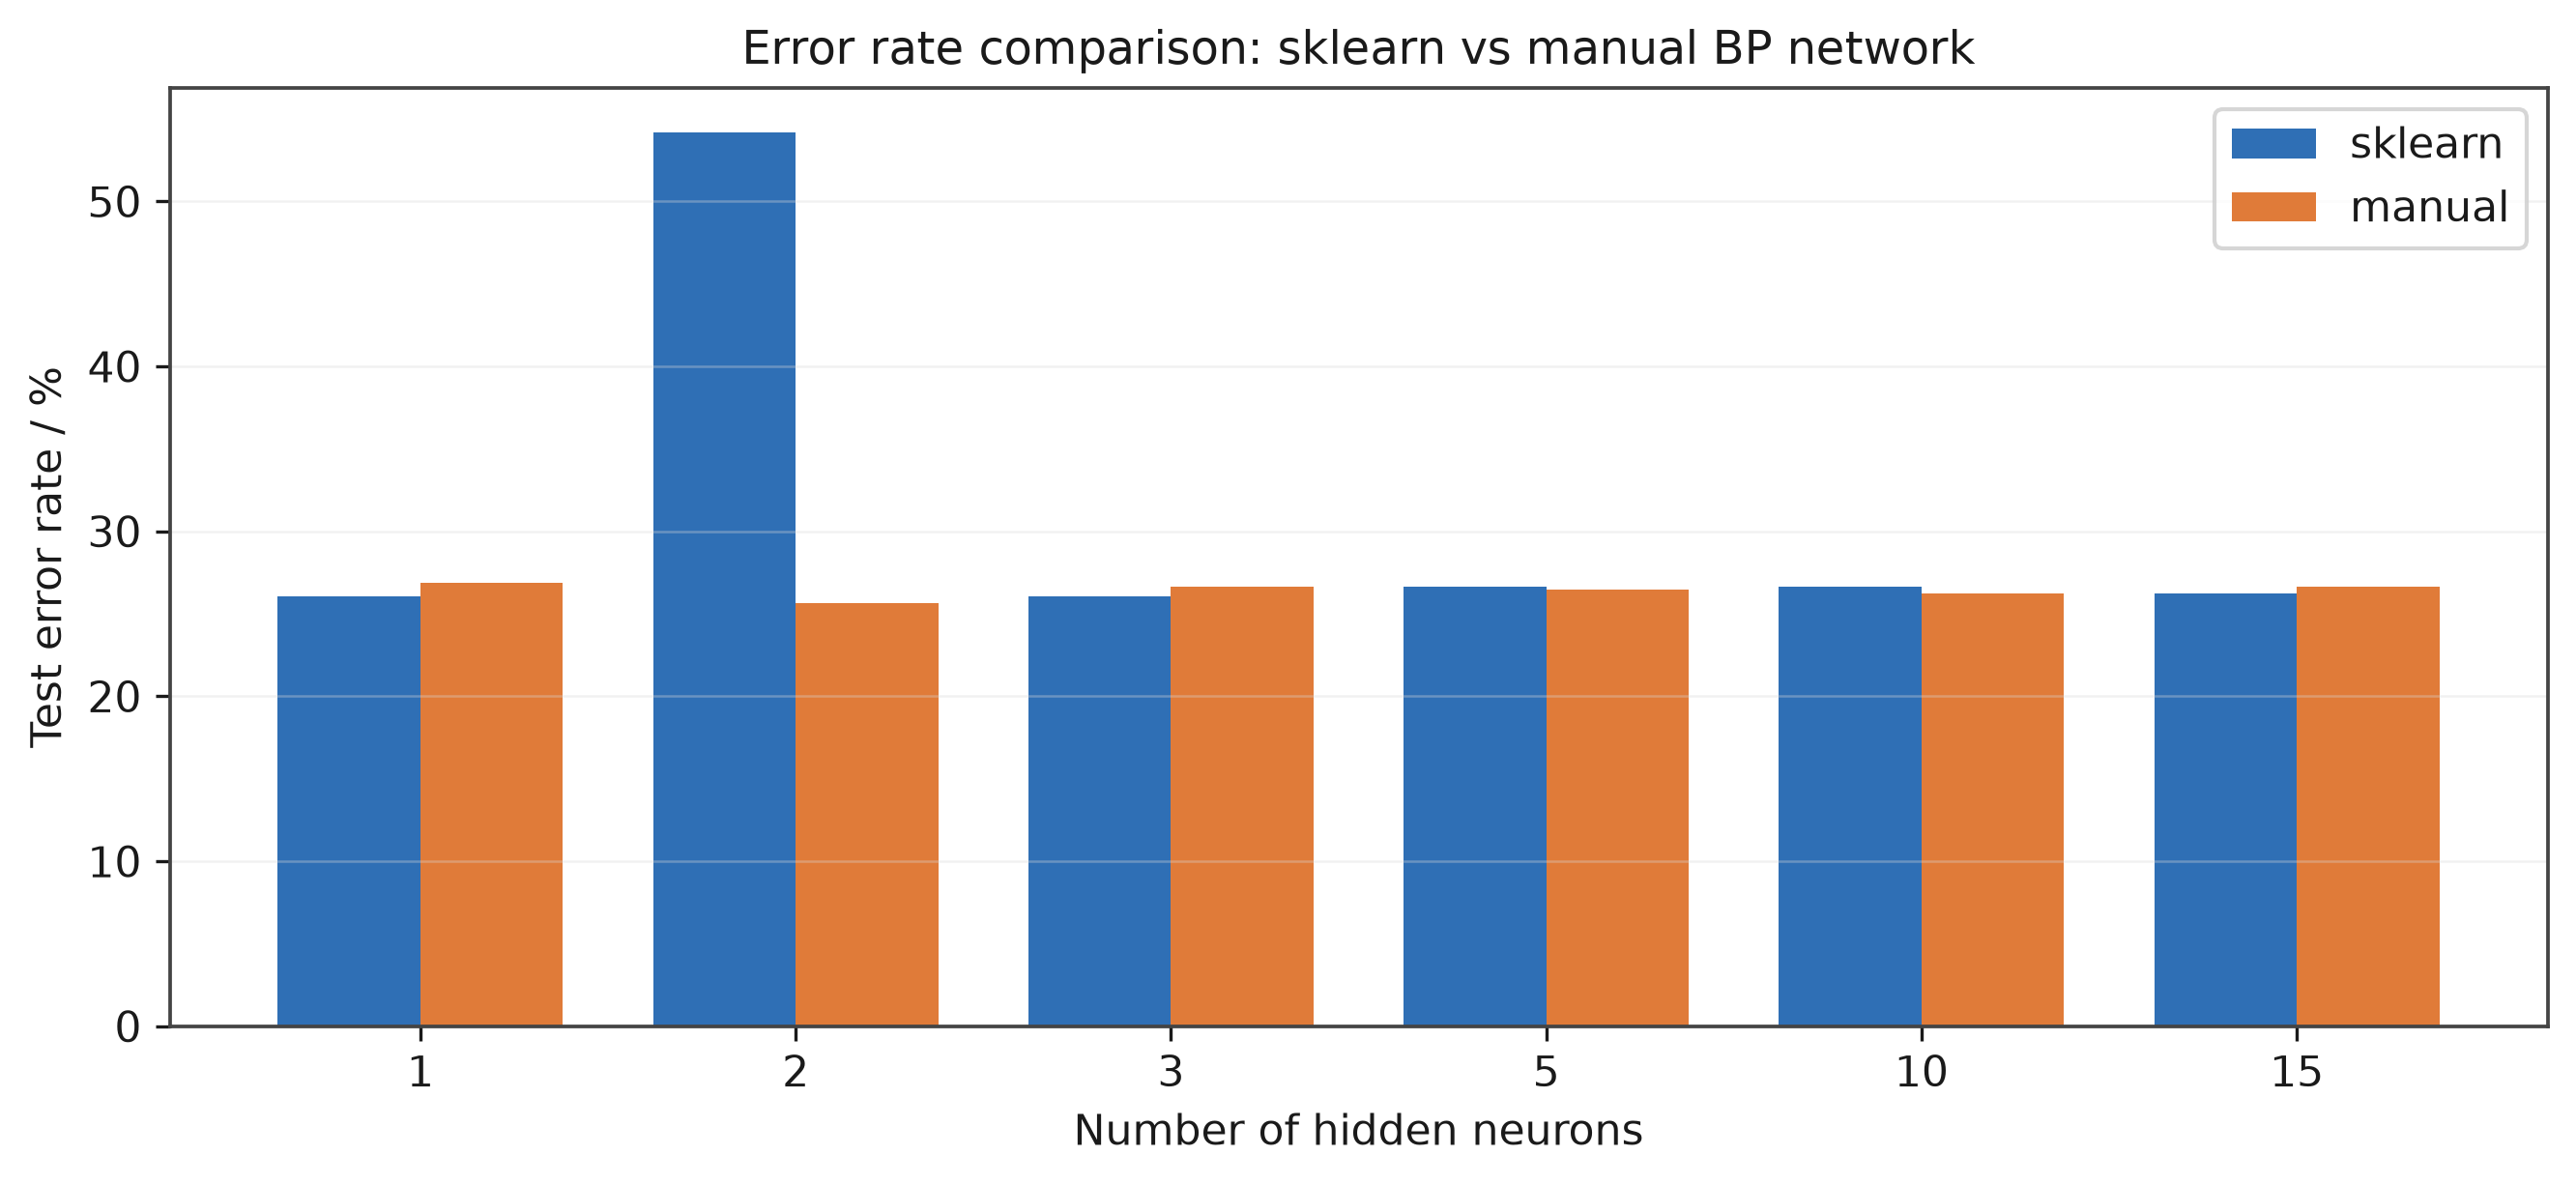

In [31]:
# 自实现：同样遍历六种隐藏层规模
my_results = []
for n in hidden_neurons:
    m = MyMLP(hidden_layer_sizes=(n,), max_iter=1000, random_state=42)
    m.fit(X_train_scaled, y_train)
    acc = m.score(X_test_scaled, y_test)
    my_results.append({"隐藏层神经元数量": n,
                       "自实现准确率": acc, "自实现错误率": 1 - acc})
my_results_df = pd.DataFrame(my_results)

merged = results_df.merge(my_results_df, on="隐藏层神经元数量")
merged["误差率之差(百分点)"] = (merged["自实现错误率"] - merged["测试错误率"]) * 100
print("两种实现的对比（测试集）：")
print(merged.round(4).to_string(index=False))

x = np.arange(len(hidden_neurons))
width = 0.38
plt.figure(figsize=(9, 4.2))
plt.bar(x - width / 2, merged["测试错误率"] * 100, width, label="sklearn")
plt.bar(x + width / 2, merged["自实现错误率"] * 100, width, label="manual")
plt.xticks(x, hidden_neurons)
plt.xlabel("Number of hidden neurons")
plt.ylabel("Test error rate / %")
plt.title("Error rate comparison: sklearn vs manual BP network")
plt.legend()
plt.grid(axis="y", alpha=0.35)
plt.tight_layout()
plt.show()
